<a href="https://colab.research.google.com/github/Krishna9423-wagh/numpy-from-scratch/blob/main/numpy_image_processing_toolkit_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Image processing with NumPy array operations: grayscale, flip, rotate, channel split, collage.

Load a built-in sample image



Shape: (512, 512, 3)
Dtype: uint8
Min/Max: 0 255


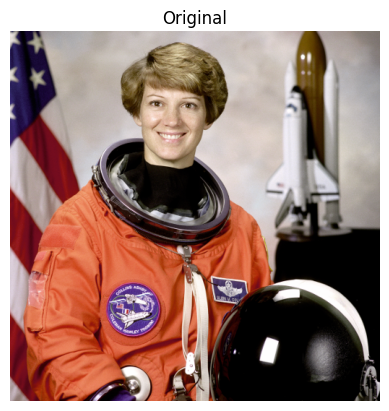

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

img = data.astronaut()

print("Shape:", img.shape)
print("Dtype:", img.dtype)
print("Min/Max:", img.min(), img.max())

plt.imshow(img)
plt.title("Original")
plt.axis("off")
plt.show()

Grayscale, flip and rotate with broadcasting and transpose
Grayscale

In [10]:
weights = np.array([0.299, 0.587, 0.114])
gray = (img @ weights).astype(np.uint8)

Flip

In [11]:
flip_lr = img[:, ::-1]
flip_ud = img[::-1, :]

Rotate

In [12]:
rot_90  = img.transpose(1, 0, 2)[::-1]
rot_180 = img[::-1, ::-1]
rot_270 = img.transpose(1, 0, 2)[:, ::-1]

brightness with broadcasting

In [13]:
bright = np.clip(img.astype(int) + 60, 0, 255).astype(np.uint8)

Split channels, then stack them into a collage

In [14]:
R = img[:, :, 0]
G = img[:, :, 1]
B = img[:, :, 2]

Collage

In [15]:
gray_rgb = np.stack([gray]*3, axis=2)


red_only = np.zeros_like(img)
red_only[:, :, 0] = R

green_only = np.zeros_like(img)
green_only[:, :, 1] = G

blue_only = np.zeros_like(img)
blue_only[:, :, 2] = B

top    = np.hstack([img, gray_rgb, flip_lr])
bottom = np.hstack([red_only, green_only, blue_only])
collage = np.vstack([top, bottom])

print(collage.shape)

(1024, 1536, 3)


Show results with plt.imshow, and %timeit vs pixel loops

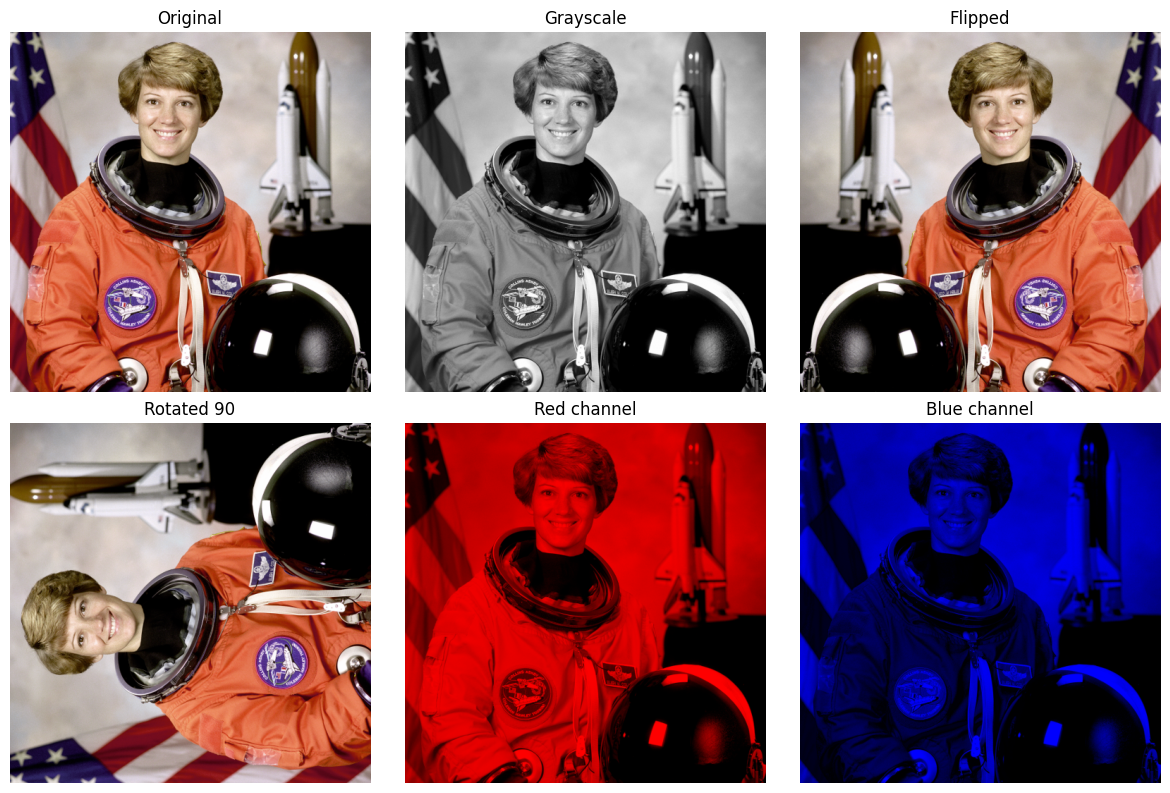

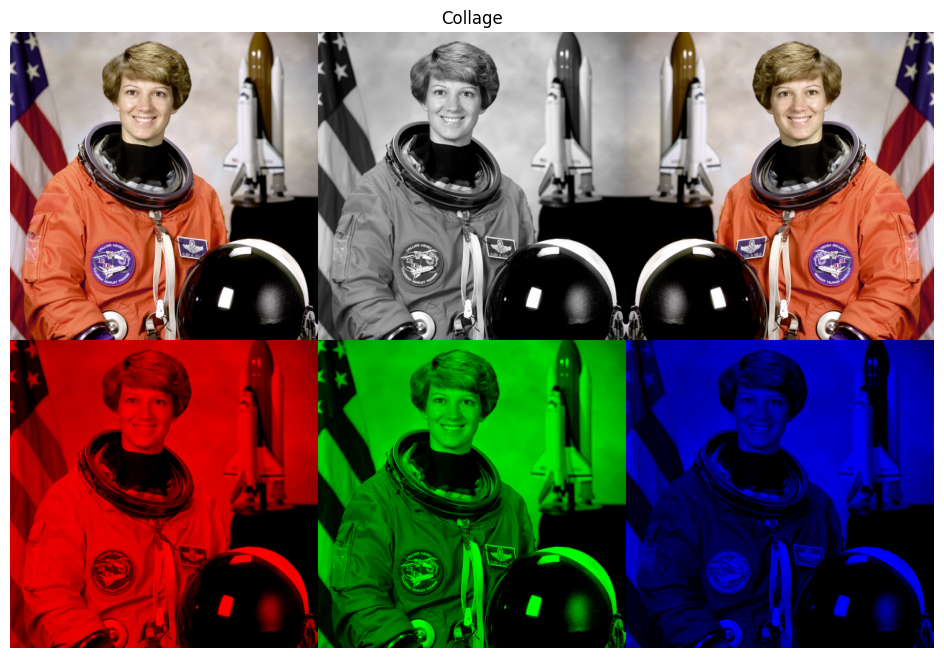

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
items = [(img, "Original"), (gray, "Grayscale"), (flip_lr, "Flipped"),
         (rot_90, "Rotated 90"), (red_only, "Red channel"), (blue_only, "Blue channel")]

for ax, (im, title) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
plt.imshow(collage); plt.axis("off"); plt.title("Collage")
plt.show()

%timeit: NumPy vs pixel loops

In [17]:
def gray_loop(image):
    h, w, _ = image.shape
    out = np.zeros((h, w), dtype=np.uint8)
    for i in range(h):
        for j in range(w):
            r, g, b = image[i, j]
            out[i, j] = 0.299*r + 0.587*g + 0.114*b
    return out

def gray_numpy(image):
    return (image @ weights).astype(np.uint8)

In [18]:
%timeit gray_loop(img)

2.39 s ± 416 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [19]:
%timeit gray_numpy(img)

1.9 ms ± 206 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)
